# Machine Learning Final Project: 
## Neuro-Symbolic Differentiable Rule Extractor

**Creator**: Iman Sharifi, G46454668

In [1]:
import numpy as np

import numpy as np

def interpret_neuron_weights_(pred_values, Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        pred_value: The predicted value to be used in interpretation. it is a scalar value between 0 and 1.
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # Find predicate value of a given neuron
        pred_value = pred_values[i]

        # compute {pred_value*weights[0], (1-pred_value)*weights[1], weights[2]}
        new_weights = [pred_value * weights[0], (1 - pred_value) * weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

import numpy as np

def interpret_neuron_weights(Weights):
    """
    Interpret the weights of neurons and return a list of 'b_{i}', 'not(b_{i})', or '1'.

    Args:
        weights (numpy.ndarray): A 2D numpy array where each row corresponds to the weights of a neuron.

    Returns:
        list: A list of strings ('b_{i}', 'not(b_{i})', or '1') for each neuron.
    """
    

    interpretations = []
    for i, weights in enumerate(Weights):

        # compute {weights[0], weights[1], weights[2]}
        new_weights = [weights[0], weights[1], weights[2]]

        max_index = np.argmax(new_weights)
        if max_index == 0:
            interpretations.append(f'b{i+1}')
            continue
        elif max_index == 1:
            interpretations.append(f'not(b{i+1})')
            continue
        else:
            interpretations.append('1')
    return interpretations

## Learning desire rules from posivitive and negative examples and boolean inputs

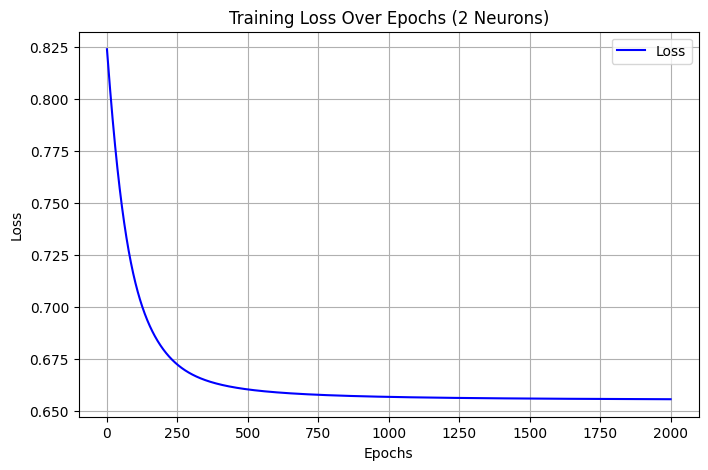


Final Weights of the Network:

Extracted Rule:
h :- b1 and not(b2).


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random
from collections import Counter

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        # weights = torch.sigmoid(self.raw_weights) 
        weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 2  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# Generate Synthetic Data (Binary Classification with Two Inputs)
# torch.manual_seed(42)
num_samples = 10

X_train = (torch.rand(num_samples, num_neurons) > 0.5).float()  # 100 samples, 2 input features
y_train = (X_train[:, 0] * (1-X_train[:, 1])).float()  # Threshold for classification for classification

# Model, Loss, Optimizer
model_nsre = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
# criterion = nn.BCELoss()  # Binary Cross-Entropy loss
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model_nsre.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model_nsre(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses_nsre.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Corrected code
Weights_nsre = []
Rounded_weights_nsre = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model_nsre.neurons):
    weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy()
    # Convert weights to a list
    weights = weights.tolist()
    Weights_nsre.append(weights)


# Repeat the process for each sample and find the final rule and print it
Extracted_rules = []
preds = interpret_neuron_weights(Weights_nsre)  # Pass pred_values and Weights_nsre
refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
rule = f"h :- " + " and ".join(refined_preds) + "."
print("\nExtracted Rule:")
print(rule)

In [4]:
# Test the model with new data
torch.manual_seed(41)
num_samples = 100
X_test = (torch.rand(num_samples, 2) > 0.5).float()
y_test = (X_test[:, 0] * (1-X_test[:, 1])).float()
print("\nTarget Values:")
print(y_test)
with torch.no_grad():
    test_predictions = model_nsre(X_test).squeeze()
    # truth values of the predictions (if output is greater than 0.5, it's 1, else 0)
    test_predictions = (test_predictions > 0.5).float()
    # Find the accuracy
    accuracy = (test_predictions == y_test).float().mean()
    print("NSRE accuracy:", accuracy.item())



Target Values:
tensor([0., 1., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 1., 0., 0., 1., 0., 0.,
        1., 1., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 1., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 1., 0., 0., 0., 1.])
NSRE accuracy: 1.0


## Learning $y  \leftarrow x_1 \land x_2$ for probabilistic inputs

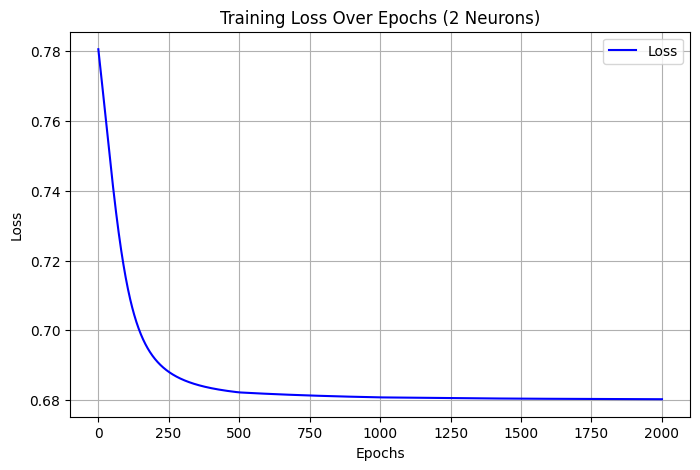


Final Weights of the Network:
Neuron 1: [0.0016031735576689243, 0.9951764345169067, 0.0032203516457229853]
Neuron 2: [0.9951317310333252, 0.0019962473306804895, 0.002871959935873747]

Extracted Rule:
h :- not(b1) and b2.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random
from collections import Counter

# Stabilize reproducibility
torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        # weights = torch.sigmoid(self.raw_weights)
        weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1

        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]
            outputs.append(neuron(xi))
        return torch.exp(sum(outputs))

# Settings
num_neurons = 2
input_dim = num_neurons + 2
num_samples = 50

# Synthetic Data
X_train = torch.rand(num_samples, input_dim)
# y_train = (X_train[:, 0] > -1).float()    # h :- 1.
# y_train = (X_train[:, 0] > 0.5).float()   # h :- b1
# y_train = (X_train[:, 1] > 0.5).float()   # h :- b2
# y_train = ((1 - X_train[:, 0]) > 0.5).float()   # h :- not b1
# y_train = ((1 - X_train[:, 1]) > 0.5).float()   # h :- not b2
# y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float() # h :- b1 and b2
# y_train = (X_train[:, 0] * (1-X_train[:, 1]) > 0.25).float() # h :- b1 and not b2
y_train = ((1 - X_train[:, 0]) * X_train[:, 1] > 0.25).float() # h :- not b1 and b2
# y_train = ((1 - X_train[:, 0]) * (1 - X_train[:, 1]) > 0.25).float() # h :- not b1 and not b2

# Model setup
model_nsre = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Training Loop
num_epochs = 2000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Output final weights
Weights_nsre = []
for i, neuron in enumerate(model_nsre.neurons):
    # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
    weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
    Weights_nsre.append(weights)

print("\nFinal Weights of the Network:")
for i, weights in enumerate(Weights_nsre):
    print(f"Neuron {i+1}: {weights}")

preds = interpret_neuron_weights(Weights_nsre)  # Pass pred_values and Weights_nsre
refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
rule = f"h :- " + " and ".join(refined_preds) + "."
print("\nExtracted Rule:")
print(rule)

## Learning More than one rule using NSDRE

## Example rule: 

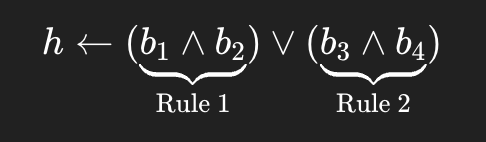

### $h \leftarrow h_1 \vee h_2$

### $h_1 \leftarrow b_1 \wedge b_2$

### $h_2 \leftarrow b_3 \wedge b_4$

## Considering a simple Fuzzy Disjunction Layer (like DFORL paper) -> didn't work

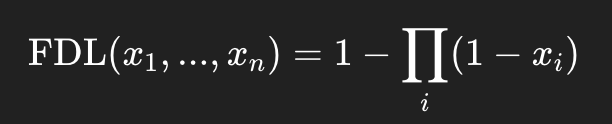

In [110]:
import torch
import torch.nn as nn
import torch.optim as optim
from copy import deepcopy
import matplotlib.pyplot as plt

# Define CustomNeuron and FuzzyDisjunctionNet
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.randn(3) * 0.1)  # Small init to prevent saturation

    def forward(self, x):
        self.weights = torch.softmax(self.raw_weights, dim=0)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = self.weights[0] * x1
        X2 = self.weights[1] * x2
        X3 = self.weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        self.saved_weights = []
        self.entropies = []
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            rule_weights = []
            entropy_sum = 0.0
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
                weights = neuron.weights
                rule_weights.append(weights)
                entropy_sum += -(weights * torch.log(weights + 1e-6)).sum()
            rule_vector = torch.cat(rule_weights)
            self.saved_weights.append(rule_vector)
            self.entropies.append(entropy_sum)
            rule_output = torch.exp(sum(conjunctions))
            rule_outputs.append(rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r

        return fuzzy_or

## The most stable version of the code:

1 - Added Multiple Initial values

2 - Added entropy for weight exploration 

Restart 1/5 Final Loss: 0.6356
Restart 2/5 Final Loss: 0.6527
Restart 3/5 Final Loss: 0.6527
Restart 4/5 Final Loss: 0.6358
Restart 5/5 Final Loss: 0.6356


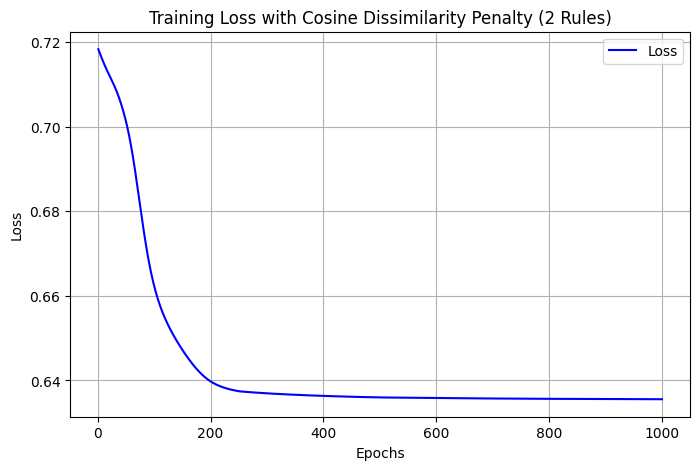

The most repeated rule is: 'h1 :- b1 and not(b2).'
It appears 453 times out of 500.
The most repeated rule is: 'h2 :- b3 and b4.'
It appears 489 times out of 500.

Final Rule:
h :- b1 and not(b2) or b3 and b4.


In [122]:
# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 500
num_epochs = 1000
num_restarts = 5
similarity_weight = 0.1
entropy_weight = 0.01

# Dataset
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Cosine similarity function
cosine = nn.CosineSimilarity(dim=1)

# Multi-Restart Training
best_state_dict = None
best_loss = float('inf')
best_losses = []

for restart in range(num_restarts):
    model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=250, gamma=0.5)

    losses_nsre = []

    for epoch in range(num_epochs):
        optimizer.zero_grad()
        outputs = model_nsre(X_train).squeeze()
        bce_loss = criterion(outputs, y_train)

        # Cosine similarity loss
        penalty = 0.0
        for i in range(num_rules):
            for j in range(i + 1, num_rules):
                wi = model_nsre.saved_weights[i].view(num_neurons_per_rule, -1)
                wj = model_nsre.saved_weights[j].view(num_neurons_per_rule, -1)
                pairwise_sim = cosine(wi, wj).mean()
                penalty += pairwise_sim

        # Entropy regularization for exploration
        entropy_term = sum(model_nsre.entropies)

        total_loss = bce_loss + similarity_weight * penalty - entropy_weight * entropy_term
        total_loss.backward()
        nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        losses_nsre.append(total_loss.item())

    final_loss = losses_nsre[-1]
    print(f"Restart {restart+1}/{num_restarts} Final Loss: {final_loss:.4f}")
    if final_loss < best_loss:
        best_loss = final_loss
        best_state_dict = deepcopy(model_nsre.state_dict())
        best_losses = losses_nsre

# Load the best model
best_model = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
best_model.load_state_dict(best_state_dict)

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Cosine Dissimilarity Penalty ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " or ".join(Final_rules) + "."
print("\nFinal Rule:")
print(final_rule)


In [120]:

# Extract final weights for inspection
Weights_nsre = []
for rule in best_model.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

Weights_nsre


[[[0.00794021226465702, 0.009331383742392063, 0.9827284216880798],
  [0.006890994496643543, 0.014530273154377937, 0.9785787463188171],
  [0.995484471321106, 0.002947787754237652, 0.0015678091440349817],
  [0.9918423891067505, 0.004976964555680752, 0.0031807448249310255]],
 [[0.9893883466720581, 0.006150400266051292, 0.004461193922907114],
  [0.003400120185688138, 0.9944357872009277, 0.0021641075145453215],
  [0.013039696961641312, 0.11625037342309952, 0.8707099556922913],
  [0.004661816172301769, 0.1413939893245697, 0.8539441823959351]]]

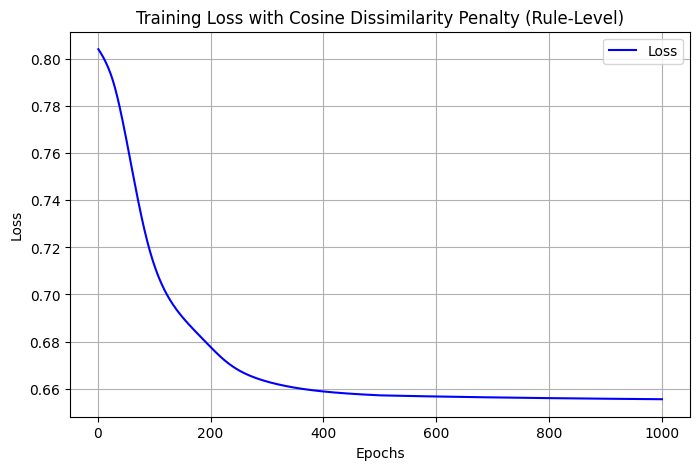

The most repeated rule is: 'h1 :- b1 and not(b2).'
It appears 499 times out of 500.
The most repeated rule is: 'h2 :- b3 and b4.'
It appears 499 times out of 500.

Final Rule:
h :- b1 and not(b2) or b3 and b4.


In [117]:


# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 500

# Generate Synthetic Data
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Model, Loss, Optimizer
model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

cosine = nn.CosineSimilarity(dim=0)
similarity_weight = 0.1

# Training Loop
num_epochs = 1000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    bce_loss = criterion(outputs, y_train)

    penalty = 0.0
    for i in range(num_rules):
        for j in range(i + 1, num_rules):
            wi = model_nsre.saved_weights[i]
            wj = model_nsre.saved_weights[j]
            pairwise_sim = cosine(wi, wj)
            penalty += pairwise_sim

    total_loss = bce_loss + similarity_weight * penalty
    total_loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(total_loss.item())

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss with Cosine Dissimilarity Penalty (Rule-Level)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in model_nsre.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Rule interpretation
Predicate_values = X_train
input_dim = 4

Final_rules = []
for rule_num, weights in enumerate(Weights_nsre):
    Extracted_rules = []
    for i in range(len(Predicate_values)):
        pred_values = Predicate_values[i].numpy()
        preds = interpret_neuron_weights_(pred_values, weights)
        refined_preds = [pred for pred in preds if pred != '1']
        rule = f"h{rule_num+1} :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    rule_counts = Counter(Extracted_rules)
    most_common_rule, count = rule_counts.most_common(1)[0]
    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

    Final_rules.append(most_common_rule)

# remove the "h{i+1} :- " part from each rule
Final_rules = [rule.replace(f"h{rule_num+1} :- ", "") for rule_num, rule in enumerate(Final_rules)]

# remove the "."
Final_rules = [rule.replace(".", "") for rule in Final_rules]

# convert the rules to a single rule
final_rule = "h :- " + " or ".join(Final_rules) + "."
print("\nFinal Rule:")
print(final_rule)


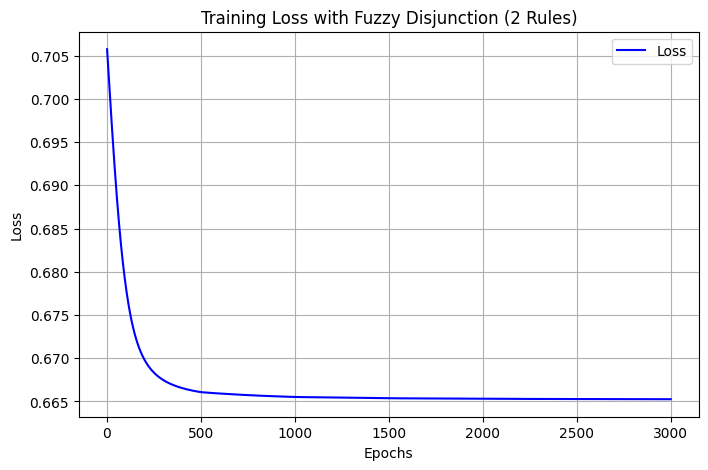

The most repeated rule is: 'h :- b1 and b2 and b3 and b4.'
It appears 19 times out of 20.
The most repeated rule is: 'h :- b1 and b2 and b3 and b4.'
It appears 19 times out of 20.


In [31]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Custom Activation Function for a Neuron (Conjunction)
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # weights = torch.sigmoid(self.raw_weights)  # Normalize to [0,1]
        weights = torch.softmax(self.raw_weights, dim=0)  # Ensure weights sum to 1

        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Fuzzy conjunction with stabilizing term
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Each rule is a group of neurons (AND), and model aggregates them with fuzzy OR
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim

        # Create a list of rule modules, each with its own set of neurons
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]  # Distribute input features
                conjunctions.append(neuron(xi))
            rule_output = torch.exp(sum(conjunctions))  # Fuzzy AND then exp
            rule_outputs.append(rule_output)

        # Fuzzy OR (S-norm: algebraic sum)
        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r  # Algebraic sum S-norm

        return fuzzy_or

# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000

# Synthetic Data with Ground Truth: h <- b1 & b2 or b3 & b4
# torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Model, Loss, Optimizer
model_nsre = FuzzyDisjunctionNet(num_rules=num_rules, num_neurons_per_rule=num_neurons_per_rule, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Training Loop
num_epochs = 3000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Fuzzy Disjunction ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in model_nsre.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Create 10 random samples like the training data for Predicate_values
Predicate_values = X_train  # Use the first 10 samples from the training data

# Repeat the process for each sample and find the final rule and print it

for weights in Weights_nsre:
    Extracted_rules = []
    for i in range(20):
        # Generate random predicate values between 0 and 1
        pred_values = Predicate_values[i].numpy()  # Convert to numpy array for compatibility

        preds = interpret_neuron_weights_(pred_values, weights)  # Pass pred_values and weights
        refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    # print("\nExtracted Rules:")
    # for rule in Extracted_rules:
    #     print(rule)
    # Count the occurrences of each rule
    rule_counts = Counter(Extracted_rules)

    # Find the most common rule
    most_common_rule, count = rule_counts.most_common(1)[0]

    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")


## Apply Teacher Forcing Mask (Not a good Idea)

Use our knowledge of the dataset to see which output is related to which output. Then update each rule when it is associated with the corresponding output.

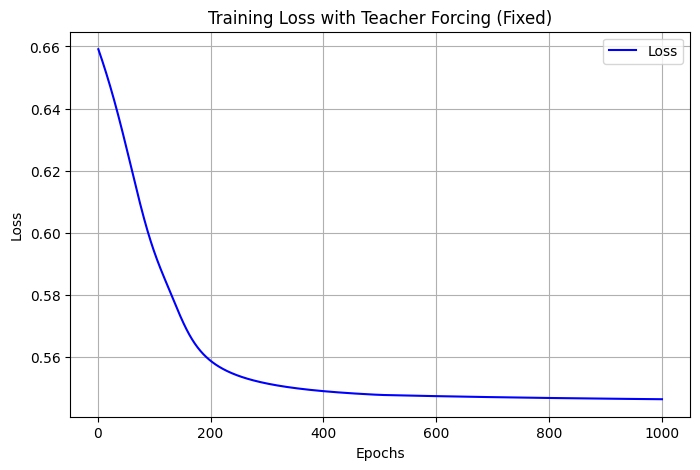

The most repeated rule is: 'h :- .'
It appears 20 times out of 20.
The most repeated rule is: 'h :- b3.'
It appears 20 times out of 20.


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np

# Custom Activation Function for a Neuron (Conjunction)
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-1 + 2 * torch.rand(3))

    def forward(self, x):
        # weights = torch.sigmoid(self.raw_weights)
        weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# FuzzyDisjunctionNet with Teacher Forcing
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x, rule_mask=None):
        rule_outputs = []
        for rule in self.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
            rule_output = torch.exp(sum(conjunctions))
            rule_outputs.append(rule_output)

        rule_outputs = torch.stack(rule_outputs, dim=1)  # (batch_size, num_rules)

        if rule_mask is not None:
            rule_mask = rule_mask.to(rule_outputs.device).float()
            rule_mask = rule_mask.view_as(rule_outputs)  # ensure same shape
            rule_outputs = rule_outputs * rule_mask

        fuzzy_or = rule_outputs[:, 0]
        for i in range(1, rule_outputs.shape[1]):
            fuzzy_or = fuzzy_or + rule_outputs[:, i] - fuzzy_or * rule_outputs[:, i]

        return fuzzy_or

# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000

torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Create rule mask for teacher forcing
mask = torch.zeros(num_samples, num_rules)
mask[:, 0] = ((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)).float()
mask[:, 1] = ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5)).float()

# Model, Loss, Optimizer
model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Training Loop
num_epochs = 1000  # reduce for stability
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train, rule_mask=mask).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss with Teacher Forcing (Fixed)")
plt.legend()
plt.grid(True)
plt.show()

# Extract final weights
Weights_nsre = []
for rule in model_nsre.rules:
    rule_weights = []
    for neuron in rule:
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Create 10 random samples like the training data for Predicate_values
Predicate_values = X_train  # Use the first 10 samples from the training data

# Repeat the process for each sample and find the final rule and print it

for weights in Weights_nsre:
    Extracted_rules = []
    for i in range(20):
        # Generate random predicate values between 0 and 1
        pred_values = Predicate_values[i].numpy()  # Convert to numpy array for compatibility

        preds = interpret_neuron_weights_(pred_values, weights)  # Pass pred_values and weights
        refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    # print("\nExtracted Rules:")
    # for rule in Extracted_rules:
    #     print(rule)
    # Count the occurrences of each rule
    rule_counts = Counter(Extracted_rules)

    # Find the most common rule
    most_common_rule, count = rule_counts.most_common(1)[0]

    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")

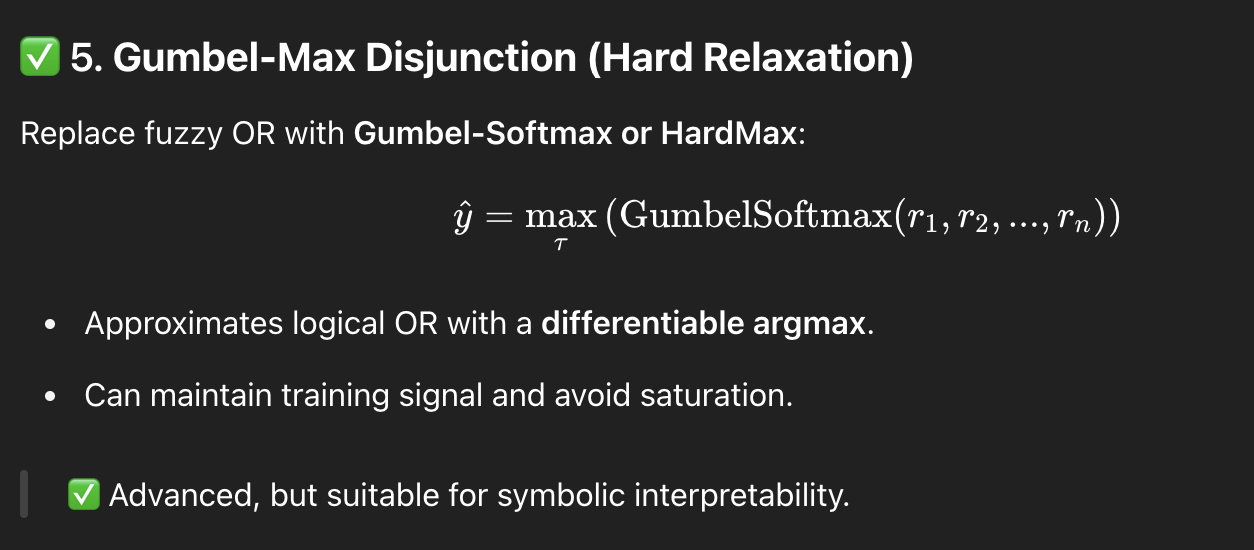

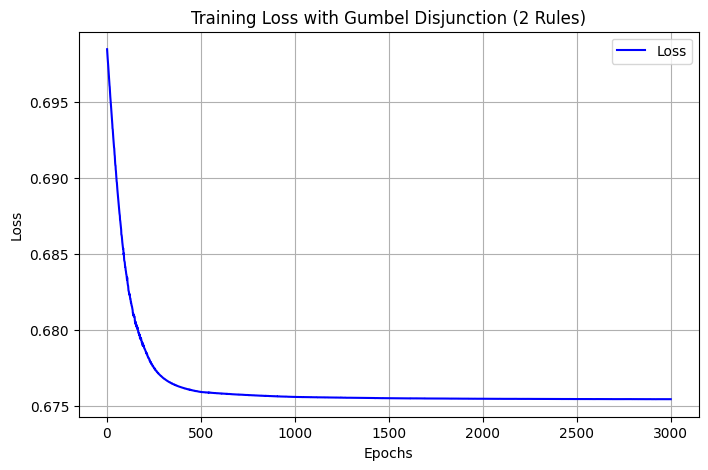

The most repeated rule is: 'h :- b1 and not(b2) and b3 and b4.'
It appears 19 times out of 20.
The most repeated rule is: 'h :- b1 and not(b2) and b3 and b4.'
It appears 19 times out of 20.


In [30]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter

# Custom Activation Function for a Neuron (Conjunction)
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))

    def forward(self, x):
        # weights = torch.sigmoid(self.raw_weights)
        weights = torch.softmax(self.raw_weights, dim=0)  # Normalize weights to sum to 1
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Each rule is a group of neurons (AND), and model aggregates them with Gumbel-Max OR
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim, gumbel_temp=0.5):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.gumbel_temp = gumbel_temp

        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        rule_outputs = []

        for rule in self.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
            rule_output = torch.exp(sum(conjunctions))  # Fuzzy AND then exp
            rule_outputs.append(rule_output)

        rule_outputs = torch.stack(rule_outputs, dim=1)  # shape: (batch, num_rules)

        # Gumbel-Max OR approximation using Gumbel-Softmax
        gumbels = -torch.empty_like(rule_outputs).exponential_().log()
        gumbel_logits = (rule_outputs.log() + gumbels) / self.gumbel_temp
        softmaxed = torch.softmax(gumbel_logits, dim=1)
        output = (softmaxed * rule_outputs).sum(dim=1)

        return output

# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 3000

# torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & ((1 - X_train[:, 1]) > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Model, Loss, Optimizer
model_nsre = FuzzyDisjunctionNet(num_rules, num_neurons_per_rule, input_dim, gumbel_temp=0.5)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Training Loop
num_epochs = 3000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Gumbel Disjunction ({num_rules} Rules)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in model_nsre.rules:
    rule_weights = []
    for neuron in rule:
        # weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        weights = torch.softmax(neuron.raw_weights, dim=0).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)


# Create 10 random samples like the training data for Predicate_values
Predicate_values = X_train  # Use the first 10 samples from the training data

# Repeat the process for each sample and find the final rule and print it

for weights in Weights_nsre:
    Extracted_rules = []
    for i in range(20):
        # Generate random predicate values between 0 and 1
        pred_values = Predicate_values[i].numpy()  # Convert to numpy array for compatibility

        preds = interpret_neuron_weights_(pred_values, weights)  # Pass pred_values and weights
        refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    # print("\nExtracted Rules:")
    # for rule in Extracted_rules:
    #     print(rule)
    # Count the occurrences of each rule
    rule_counts = Counter(Extracted_rules)

    # Find the most common rule
    most_common_rule, count = rule_counts.most_common(1)[0]

    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")


## Split Dataset using the Correlations between inputs and outputs (Not a Good Idea)

In [41]:
# Updated version: reduce memory load, show output via print instead of ace_tools

import torch
import itertools
from sklearn.metrics import mutual_info_score
import pandas as pd

# Sample binary inputs and outputs
torch.manual_seed(42)
num_samples = 500
num_features = 6

# Generate synthetic dataset
X = (torch.rand(num_samples, num_features) > 0.5).float()
y = (((X[:, 0] > 0.5) & (X[:, 1] > 0.5)) | ((X[:, 2] > 0.5) & (X[:, 3] > 0.5))).float()

# Generate all logical conjunctions of 1 to 3 features with possible negations
def generate_logical_features(X, max_comb_size=3):
    n = X.shape[1]
    features = {}
    X_bin = (X > 0.5).float()

    for r in range(1, max_comb_size + 1):
        for indices in itertools.combinations(range(n), r):
            for negation_mask in itertools.product([0, 1], repeat=r):
                key = []
                vals = []
                for idx, neg in zip(indices, negation_mask):
                    term = f"{'~' if neg else ''}b{idx+1}"
                    val = 1 - X_bin[:, idx] if neg else X_bin[:, idx]
                    key.append(term)
                    vals.append(val)
                name = " & ".join(key)
                conjunction = torch.prod(torch.stack(vals, dim=1), dim=1)
                features[name] = conjunction
    return features

# Compute mutual information scores
def compute_feature_correlations(features, y):
    y_bin = y.int().numpy()
    correlations = {}
    for name, values in features.items():
        x_bin = values.int().numpy()
        correlations[name] = mutual_info_score(x_bin, y_bin)
    return dict(sorted(correlations.items(), key=lambda x: -x[1]))

# Generate and rank features
logical_features = generate_logical_features(X, max_comb_size=3)
correlated_terms = compute_feature_correlations(logical_features, y)

# Prepare top correlated features
top_features_df = pd.DataFrame(list(correlated_terms.items()), columns=["Feature", "Mutual_Info"])
top_features_df = top_features_df[top_features_df["Mutual_Info"] > 0]
top_features_df = top_features_df.sort_values(by="Mutual_Info", ascending=False).head(20)

# Print results
print("Top Correlated Logical Features:")
print(top_features_df.to_string(index=False))


Top Correlated Logical Features:
      Feature  Mutual_Info
      b1 & b2     0.291232
      b3 & b4     0.248098
    ~b2 & ~b3     0.206153
    ~b2 & ~b4     0.191691
    ~b1 & ~b3     0.184652
    ~b1 & ~b4     0.164247
 b1 & b2 & b5     0.146344
 b1 & b2 & b6     0.137422
 b1 & b2 & b3     0.130831
 b3 & b4 & b5     0.130831
 b1 & b2 & b4     0.128652
b1 & b2 & ~b4     0.122170
b1 & b2 & ~b3     0.120027
 b2 & b3 & b4     0.117892
b1 & b2 & ~b6     0.113650
~b1 & b3 & b4     0.111541
b3 & b4 & ~b6     0.111541
 b1 & b3 & b4     0.107350
 b3 & b4 & b6     0.107350
           b2     0.106224


## Data Curriculum or Masking (Phase Training) -> (didn't work) 

When we train one rule, it considers the rest of the dataset as noise. If this noise percentage is too large, it cannot find the first rule. If the first rule is wrong, then the second rule is wrong as well. Therefore, there should be a cascading collapse into the learning process.

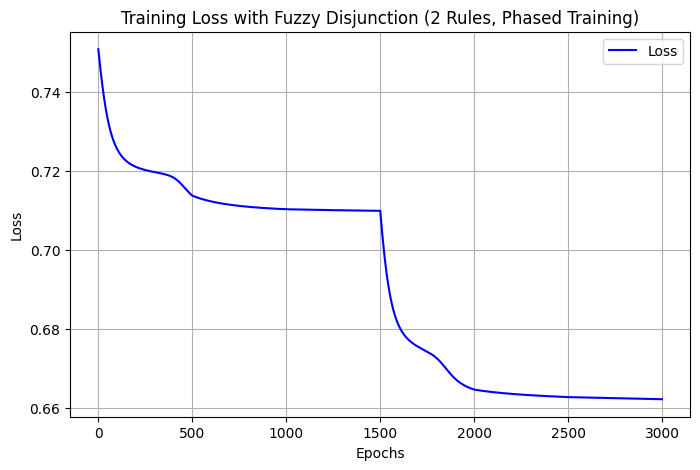

The most repeated rule is: 'h :- b1 and b2 and b3 and b4.'
It appears 17 times out of 20.
The most repeated rule is: 'h :- b1 and b2 and b3 and b4.'
It appears 12 times out of 20.


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np# Updated version: reduce memory load, show output via print instead of ace_tools
from collections import Counter

# Custom Activation Function for a Neuron (Conjunction)
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-1 + 2 * torch.rand(3))

    def forward(self, x):
        weights = torch.sigmoid(self.raw_weights)
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)
        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3
        stable_input = X1 + X2 + X3 - (X1 * X2 + X1 * X3 + X2 * X3) + (X1 * X2 * X3) + 1e-6
        return torch.log(stable_input)

# Each rule is a group of neurons (AND), and model aggregates them with fuzzy OR
class FuzzyDisjunctionNet(nn.Module):
    def __init__(self, num_rules, num_neurons_per_rule, input_dim):
        super(FuzzyDisjunctionNet, self).__init__()
        self.num_rules = num_rules
        self.num_neurons_per_rule = num_neurons_per_rule
        self.input_dim = input_dim
        self.rules = nn.ModuleList([
            nn.ModuleList([CustomNeuron() for _ in range(num_neurons_per_rule)])
            for _ in range(num_rules)
        ])

    def forward(self, x):
        rule_outputs = []
        for rule in self.rules:
            conjunctions = []
            for i, neuron in enumerate(rule):
                xi = x[:, [i % self.input_dim]]
                conjunctions.append(neuron(xi))
            rule_output = torch.exp(sum(conjunctions))  # Fuzzy AND then exp
            rule_outputs.append(rule_output)

        fuzzy_or = rule_outputs[0]
        for r in rule_outputs[1:]:
            fuzzy_or = fuzzy_or + r - fuzzy_or * r  # Algebraic sum S-norm

        return fuzzy_or

# Parameters
num_rules = 2
num_neurons_per_rule = 4
input_dim = 4
num_samples = 1000

# Synthetic Data with Ground Truth: h <- b1 & b2 or b3 & b4
torch.manual_seed(42)
X_train = torch.rand(num_samples, input_dim)
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()

# Phase-based training
model_nsre = FuzzyDisjunctionNet(num_rules=num_rules, num_neurons_per_rule=num_neurons_per_rule, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(model_nsre.parameters(), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

# Phase 1: Train first rule only
for p in model_nsre.rules[1].parameters():
    p.requires_grad = False

losses_nsre = []
for epoch in range(1500):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Phase 2: Freeze rule 1, train rule 2
for p in model_nsre.rules[0].parameters():
    p.requires_grad = False
for p in model_nsre.rules[1].parameters():
    p.requires_grad = True

optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model_nsre.parameters()), lr=0.01, weight_decay=1e-4)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=500, gamma=0.5)

for epoch in range(1500):
    optimizer.zero_grad()
    outputs = model_nsre(X_train).squeeze()
    loss = criterion(outputs, y_train)
    loss.backward()
    nn.utils.clip_grad_norm_(model_nsre.parameters(), max_norm=1.0)
    optimizer.step()
    scheduler.step()
    losses_nsre.append(loss.item())

# Plot loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(losses_nsre) + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss with Fuzzy Disjunction ({num_rules} Rules, Phased Training)")
plt.legend()
plt.grid(True)
plt.show()

# Save final weights for inspection
Weights_nsre = []
for rule in model_nsre.rules:
    rule_weights = []
    for neuron in rule:
        weights = torch.sigmoid(neuron.raw_weights).detach().numpy().tolist()
        rule_weights.append(weights)
    Weights_nsre.append(rule_weights)

# Create 10 random samples like the training data for Predicate_values
Predicate_values = X_train  # Use the first 10 samples from the training data

# Repeat the process for each sample and find the final rule and print it

for weights in Weights_nsre:
    Extracted_rules = []
    for i in range(20):
        # Generate random predicate values between 0 and 1
        pred_values = Predicate_values[i].numpy()  # Convert to numpy array for compatibility

        preds = interpret_neuron_weights_(pred_values, weights)  # Pass pred_values and weights
        refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
        rule = f"h :- " + " and ".join(refined_preds) + "."
        Extracted_rules.append(rule)

    # print("\nExtracted Rules:")
    # for rule in Extracted_rules:
    #     print(rule)
    # Count the occurrences of each rule
    rule_counts = Counter(Extracted_rules)

    # Find the most common rule
    most_common_rule, count = rule_counts.most_common(1)[0]

    print(f"The most repeated rule is: '{most_common_rule}'")
    print(f"It appears {count} times out of {len(Extracted_rules)}.")


## Adding Mislabeled data to the outputs

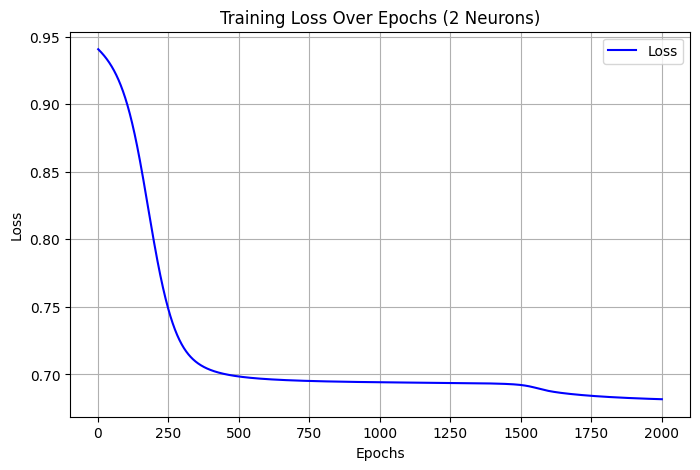


Final Weights of the Network:
The most repeated rule is: 'h :- b1 and b2.'
It appears 10 times out of 10.


In [41]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random
from collections import Counter

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 2  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 100

X_train = torch.rand(num_samples, 2)  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Adding n% of mislabeled data
num_mislabeled = int(0.1 * num_samples)
mislabeled_indices = torch.randperm(num_samples)[:num_mislabeled]
y_train[mislabeled_indices] = 1 - y_train[mislabeled_indices]

# Model, Loss, Optimizer
model_nsre = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
# criterion = nn.BCELoss()  # Binary Cross-Entropy loss
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model_nsre.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model_nsre(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses_nsre.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Corrected code
Weights_nsre = []
Rounded_weights_nsre = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model_nsre.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    # Convert weights to a list
    weights = weights.tolist()
    Weights_nsre.append(weights)

# Create 10 random samples like the training data for Predicate_values
Predicate_values = torch.rand(10, num_neurons)

# Repeat the process for each sample and find the final rule and print it
Extracted_rules = []
for i in range(10):
    # Generate random predicate values between 0 and 1
    pred_values = Predicate_values[i].numpy()  # Convert to numpy array for compatibility
    preds = interpret_neuron_weights_(pred_values, Weights_nsre)  # Pass pred_values and Weights_nsre
    refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
    rule = f"h :- " + " and ".join(refined_preds) + "."
    Extracted_rules.append(rule)

# Count the occurrences of each rule
rule_counts = Counter(Extracted_rules)

# Find the most common rule
most_common_rule, count = rule_counts.most_common(1)[0]

print(f"The most repeated rule is: '{most_common_rule}'")
print(f"It appears {count} times out of {len(Extracted_rules)}.")


### Test Models

In [ ]:
# Test the model with new data
torch.manual_seed(41)
num_samples = 1000
X_test = torch.rand(num_samples, 2)
y_test = (X_test[:, 0] * X_test[:, 1] > 0.25).float()
print("\nTarget Values:")
print(y_test)
with torch.no_grad():
    test_predictions = model_nsre(X_test).squeeze()
    # truth values of the predictions (if output is greater than 0.5, it's 1, else 0)
    test_predictions = (test_predictions > 0.25).float()
    # Find the accuracy
    accuracy = (test_predictions == y_test).float().mean()
    print("NSRE accuracy:", accuracy.item())


Target Values:
tensor([0., 0., 0., 0., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0., 0., 0., 0., 1.,
        0., 1., 1., 0., 1., 0., 1., 0., 0., 0., 1., 1., 0., 1., 0., 1., 1., 1.,
        0., 1., 0., 1., 1., 1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 1., 0., 0.,
        0., 1., 0., 1., 0., 0., 0., 0., 1., 0., 1., 0., 0., 0., 1., 0., 1., 1.,
        1., 0., 1., 0., 0., 0., 1., 0., 0., 0., 1., 1., 1., 0., 1., 0., 1., 1.,
        0., 0., 1., 0., 0., 1., 1., 1., 0., 1., 0., 1., 1., 1., 1., 0., 0., 0.,
        0., 0., 0., 1., 1., 0., 0., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 0.,
        0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0.,
        0., 1., 0., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0.,
        0., 1., 1., 0., 1., 0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 1., 0., 0.,
        1., 1., 0., 0., 0., 0., 1., 0., 0., 1., 0., 0., 0., 0., 0., 1., 1., 0.,
        1., 1., 1., 0., 0., 1., 0., 0., 1., 1., 0., 0., 0., 0., 0., 0., 1., 0.,
        0., 0., 1., 0., 

## Learning complicated rules with redundant inputs

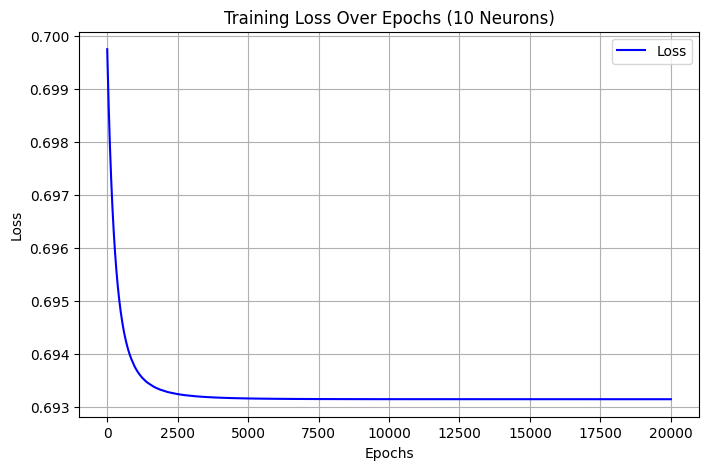


Final Weights of the Network:
The most repeated rule is: 'h :- .'
It appears 7 times out of 100.


In [47]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random
from collections import Counter

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-1 + 2 * torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 10  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
torch.manual_seed(43)
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 4]) *  (1 - X_train[:, 9])  > 0.125).float()  # Threshold for classification

# Model, Loss, Optimizer
model_nsre = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
# criterion = nn.BCELoss()  # Binary Cross-Entropy loss
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model_nsre.parameters(), lr=0.001)

# Training Loop
num_epochs = 20000
losses_nsre = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model_nsre(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses_nsre.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Corrected code
Weights_nsre = []
Rounded_weights_nsre = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model_nsre.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    # Convert weights to a list
    weights = weights.tolist()
    Weights_nsre.append(weights)

# Create 10 random samples like the training data for Predicate_values
Predicate_values = torch.rand(100, num_neurons)

# Repeat the process for each sample and find the final rule and print it
Extracted_rules = []
for i in range(len(Predicate_values)):
    # Generate random predicate values between 0 and 1
    pred_values = Predicate_values[i].numpy()  # Convert to numpy array for compatibility
    preds = interpret_neuron_weights_(pred_values, Weights_nsre)  # Pass pred_values and Weights_nsre
    refined_preds = [pred for pred in preds if pred != '1']  # Filter out '1'
    rule = f"h :- " + " and ".join(refined_preds) + "."
    Extracted_rules.append(rule)

# Count the occurrences of each rule
rule_counts = Counter(Extracted_rules)

# Find the most common rule
most_common_rule, count = rule_counts.most_common(1)[0]

print(f"The most repeated rule is: '{most_common_rule}'")
print(f"It appears {count} times out of {len(Extracted_rules)}.")


## MLP Network (Baseline)

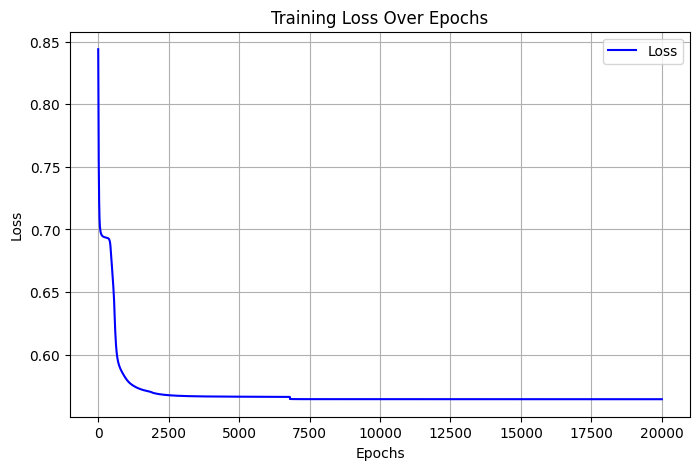


Model Weights:
fc1.weight: tensor([[-2.4150e+01,  4.6690e+00,  1.1482e+00, -2.0682e-02,  1.0620e+01,
          2.0615e-01, -1.9877e+00, -1.7746e+00,  4.0664e+00,  1.4328e+01],
        [-8.8819e-01,  8.1310e+00, -1.0886e+01,  4.9674e+00, -1.7114e+01,
         -6.3393e-01, -8.5553e-01, -2.1159e+00,  1.6808e+01, -8.8830e+00],
        [ 1.0847e+01,  5.2550e+00,  5.2360e+00,  1.0447e+01, -1.8321e+01,
          5.2630e+00,  2.7409e+00, -2.4610e+00,  4.8572e+00, -3.3427e+00],
        [-1.7172e+01,  6.4394e+00, -2.3481e+00,  6.7843e+00,  1.7107e+01,
         -2.6640e+00,  5.2743e+00, -7.6047e+00,  3.0326e+00,  1.3883e+01],
        [-1.4362e+01,  1.4006e+00,  6.1998e-01,  1.4209e+00,  9.0064e+00,
          1.5134e+00,  3.2680e+00, -2.9116e+00, -1.2052e+00,  1.5264e+01],
        [-1.4723e+01, -4.5576e-01, -6.8907e-01, -1.6944e+00,  1.2373e+01,
          1.7219e+00, -4.5594e-01, -2.7255e+00, -4.0123e+00,  1.5124e+01],
        [-1.2759e+01, -1.0581e+00,  1.1856e+00, -4.0733e+00,  1.0549e+01,
    

In [35]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Define a shallow two-layer MLP
class ShallowMLP(nn.Module):
    def __init__(self, imput_size=2, hidden_size=5):
        super(ShallowMLP, self).__init__()
        self.fc1 = nn.Linear(imput_size, hidden_size)  # Input layer to hidden layer (imput_size -> hidden_size)
        self.fc2 = nn.Linear(hidden_size, 1)  # Hidden layer to output layer (hidden_size -> 1)
        self.activation = nn.Sigmoid()  # Sigmoid activation for binary classification

    def forward(self, x):
        x = torch.sigmoid(self.fc1(x))  # Apply sigmoid activation to the hidden layer
        x = self.fc2(x)  # Output layer
        return self.activation(x)  # Apply sigmoid activation to the output

# Initialize the model, loss function, and optimizer
model_mlp = ShallowMLP(imput_size=10, hidden_size=10)
# criterion = nn.BCELoss()  # Binary Cross-Entropy loss
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model_mlp.parameters(), lr=0.01)

# Training loop
num_epochs = 20000
losses_mlp = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model_mlp(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()
    
    # Store loss for plotting
    losses_mlp.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses_mlp, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()

# Print the model's predictions and weights
with torch.no_grad():
    predictions = model_mlp(X_train).squeeze()
    # print("\nPredictions:")
    # print(predictions)
    print("\nModel Weights:")
    for name, param in model_mlp.named_parameters():
        print(f"{name}: {param.data}")

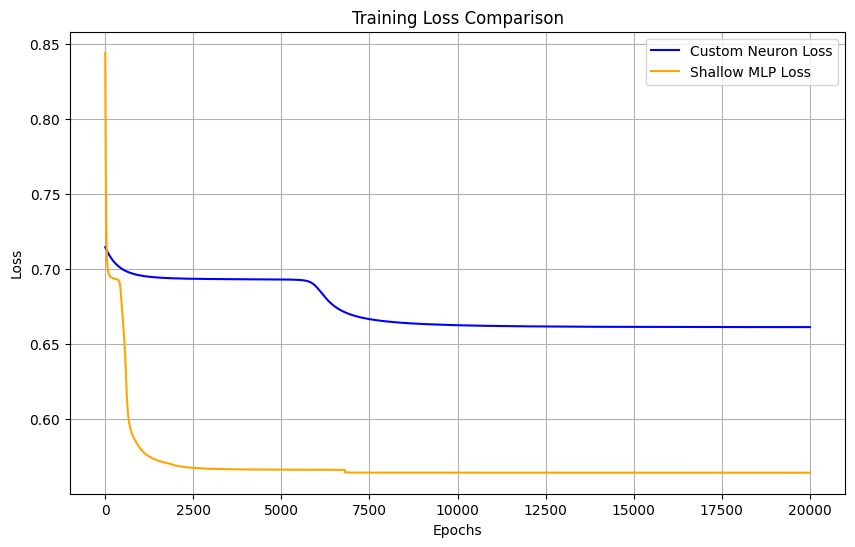

In [36]:
# Plot the losses for both models
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs + 1), losses_nsre, label="Custom Neuron Loss", color="blue")
plt.plot(range(1, num_epochs + 1), losses_mlp, label="Shallow MLP Loss", color="orange")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
# Test the model with new data
num_samples = 1000
torch.manual_seed(41)
X_test = torch.rand(num_samples, 10)
y_test = (X_test[:, 0] * (1 - X_test[:, 4]) * (1 - X_test[:, 9]) > 0.125).float()
print("\nTarget Values:")
print(y_test)
with torch.no_grad():
    test_predictions = model_nsre(X_test).squeeze()
    # truth values of the predictions (if output is greater than 0.5, it's 1, else 0)
    test_predictions = (test_predictions > 0.125).float()
    # Find the accuracy
    accuracy = (test_predictions == y_test).float().mean()
    print("NSRE accuracy:", accuracy.item())

# Test the custom neuron with new data
with torch.no_grad():
    test_predictions_mlp = model_mlp(X_test).squeeze()
    test_predictions_mlp = (test_predictions_mlp > 0.125).float()
    # print("\nTest Predictions (Custom Neuron):")
    # print(test_predictions_mlp)
    # Find the accuracy
    accuracy_mlp = (test_predictions_mlp == y_test).float().mean()
    print("MLP accuracy:", accuracy_mlp.item())


Target Values:
tensor([0., 1., 0., 1., 0., 0., 0., 1., 1., 0., 1., 0., 1., 1., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 1., 0., 1., 0., 1., 0., 1., 1., 0., 0., 0., 1., 0.,
        1., 0., 0., 0., 0., 0., 1., 0., 1., 1., 0., 0., 1., 0., 0., 0., 0., 1.,
        0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0., 1.,
        1., 1., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 1.,
        1., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 1., 0., 0., 1., 1., 0., 1., 1., 1., 0., 0., 0., 0., 0., 0., 1.,
        0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 1., 0., 1., 0., 0., 0., 0., 0.,
        1., 0., 1., 1., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0., 1.,
        0., 1., 1., 0., 0., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 1., 0., 1.,
        0., 1., 0., 1., 1., 0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 0., 1., 0.,
        1., 1., 0., 0., 0., 0., 1., 0., 0., 0., 1., 1., 0., 0., 1., 1., 0., 1.,
        1., 0., 1., 0., 

## Process Automation

Adding more inputs


Final Weights of the Network:
Neuron 1 Weights: [9.9999857e-01 5.5195892e-06 7.8472794e-06]
Neuron 2 Weights: [0.99563074 0.9513584  0.99995613]
Neuron 3 Weights: [0.9848371  0.98310167 0.9999547 ]
Neuron 4 Weights: [0.9865556  0.96545756 0.9999654 ]
Neuron 5 Weights: [7.7350114e-06 9.9999797e-01 6.4996784e-06]
Neuron 6 Weights: [0.9795855  0.97474957 0.99995506]
Neuron 7 Weights: [0.9846809  0.98272896 0.99996126]
Neuron 8 Weights: [0.9821492  0.9522313  0.99996436]
Neuron 9 Weights: [0.98733056 0.97806543 0.9999647 ]
Neuron 10 Weights: [0.97639096 0.9879716  0.99996483]


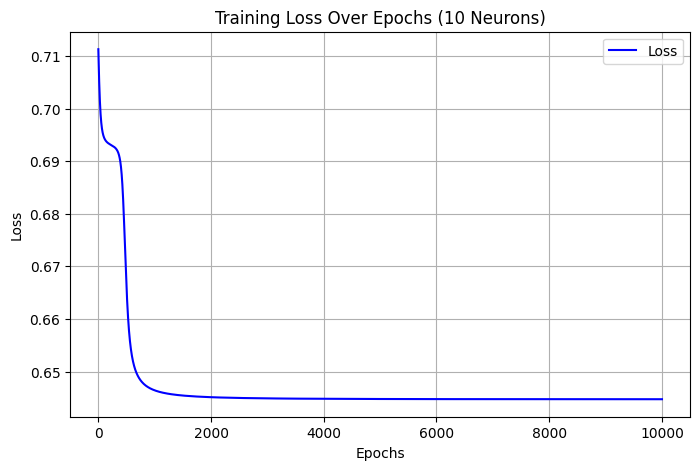

In [17]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 10  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 4]) > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 10000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

Weights = []
# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    Weights.append(weights)
    print(f"Neuron {i+1} Weights: {weights}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()


In [42]:
# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}")


Final Weights of the Network:
Neuron 1 Weights: [9.9999845e-01 5.4042021e-06 6.1680689e-06]
Neuron 2 Weights: [0.9512181 0.9875761 0.9999676]
Neuron 3 Weights: [0.97841716 0.9813565  0.99996746]
Neuron 4 Weights: [0.9813223  0.9740897  0.99995613]
Neuron 5 Weights: [5.1326178e-06 9.9999869e-01 7.2384673e-06]
Neuron 6 Weights: [0.9802649 0.9838271 0.999964 ]
Neuron 7 Weights: [0.9801875  0.9817816  0.99996245]
Neuron 8 Weights: [0.980485  0.9771955 0.9999715]
Neuron 9 Weights: [0.97496116 0.9855679  0.999977  ]
Neuron 10 Weights: [0.9935137  0.96557873 0.9999684 ]


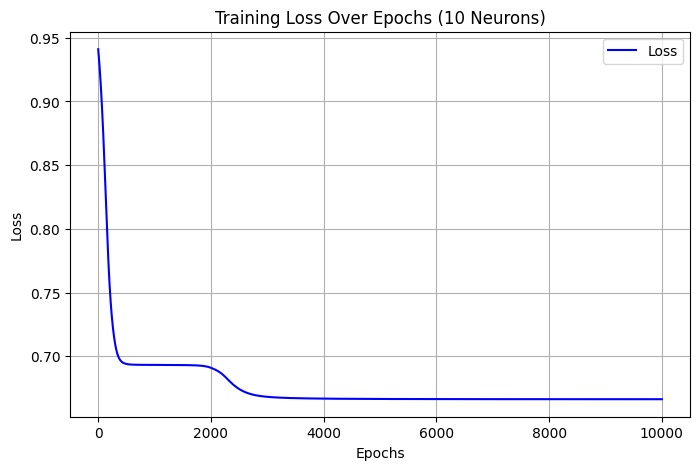


Final Weights of the Network:
Neuron 1 Weights: [1. 0. 0.]
Neuron 2 Weights: [1. 1. 1.]
Neuron 3 Weights: [1. 1. 1.]
Neuron 4 Weights: [1. 1. 1.]
Neuron 5 Weights: [0. 1. 0.]
Neuron 6 Weights: [1. 1. 1.]
Neuron 7 Weights: [1. 1. 1.]
Neuron 8 Weights: [1. 1. 1.]
Neuron 9 Weights: [1. 1. 1.]
Neuron 10 Weights: [0. 1. 0.]

Final Rule:
h :- b1 and not(b5) and not(b10).



In [24]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 10  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 4]) *  (1 - X_train[:, 9])  > 0.125).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 10000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Print Final Weights After Training
Weights = []
Rounded_weights = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    # Round the weights to the nearest number (e.g., nearest integer)
    rounded_weights = np.round(weights, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    
    Weights.append(weights)
    Rounded_weights.append(rounded_weights)
    print(f"Neuron {i+1} Weights: {rounded_weights}")

preds = interpret_neuron_weights(Rounded_weights)
refined_preds = [pred for pred in preds if pred != '1']
final_rule = f"h :- " + " and ".join(refined_preds) + "."
print("\n==========================================")
print("Final Rule:")
print(final_rule)
print("==========================================\n")


## Learning two rules

The code cannot extract two rules using one layer network. We should add the second layer to define different combinations of rules.

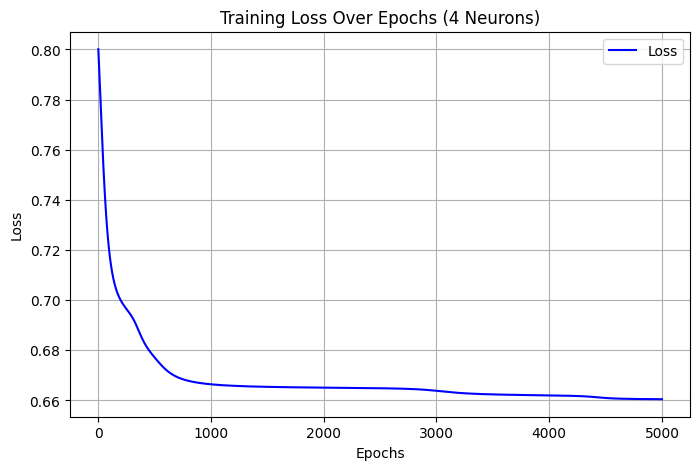


Final Weights of the Network:
Neuron 1 Weights: [1. 0. 0.]
Neuron 2 Weights: [1. 0. 1.]
Neuron 3 Weights: [1. 0. 0.]
Neuron 4 Weights: [1. 0. 0.]
Neuron 1 Weights: [1. 0. 0.]
Neuron 2 Weights: [1. 0. 0.]
Neuron 3 Weights: [1. 0. 0.]
Neuron 4 Weights: [1. 0. 1.]

h1 :- b1 and b3 and b4.

h2 :- b1 and b2 and b3.



In [5]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons1 = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.neurons2 = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs1, outputs2 = [], []
        for i, neuron in enumerate(self.neurons1):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs1.append(neuron(xi))

        for i, neuron in enumerate(self.neurons2):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs2.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output1 = torch.exp(sum(outputs1))
        output2 = torch.exp(sum(outputs2))
        return output1 + output2 - output1*output2
        # return torch.max(output1, output2)  # Use max to combine outputs

# User-Specified Number of Neurons
num_neurons = 4  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 1000
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 5000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()

    # Compute BCE loss
    loss = criterion(outputs, y_train)
    
    # Compute KL divergence between neurons1 and neurons2
    kl_divergence = 0
    for neuron1, neuron2 in zip(model.neurons1, model.neurons2):
        weights1 = torch.sigmoid(neuron1.raw_weights)
        weights2 = torch.sigmoid(neuron2.raw_weights)
        kl_divergence += torch.sum(weights1 * torch.log(weights1 / (weights2 + 1e-6) + 1e-6))

    sparsity_loss = 0
    for neuron in model.neurons1 + model.neurons2:
        weights = torch.sigmoid(neuron.raw_weights)  # Normalize weights
        softmax_weights = torch.softmax(weights, dim=0)  # Apply softmax
        entropy = -torch.sum(softmax_weights * torch.log(softmax_weights + 1e-6))  # Compute entropy
        sparsity_loss += entropy  # Accumulate entropy for all neurons
        
    # Subtract KL divergence from the loss
    total_loss = loss #+ 0.0001 * sparsity_loss #- 0.01* torch.sqrt(kl_divergence)
    
    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Print Final Weights After Training
Weights1 = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons1):
    weights1 = torch.sigmoid(neuron.raw_weights).detach().numpy()
    weights1 = np.round(weights1, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    Weights1.append(weights1)
    print(f"Neuron {i+1} Weights: {weights1}")

Weights2 = []
for i, neuron in enumerate(model.neurons2):
    weights2 = torch.sigmoid(neuron.raw_weights).detach().numpy()
    weights2 = np.round(weights2, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    Weights2.append(weights2)
    print(f"Neuron {i+1} Weights: {weights2}")

preds1 = interpret_neuron_weights(Weights1)
refined_preds1 = [pred for pred in preds1 if pred != '1']
print("==========================================\n")
print(f"h1 :- " + " and ".join(refined_preds1) + ".")
preds2 = interpret_neuron_weights(Weights2)
refined_preds2 = [pred for pred in preds2 if pred != '1']
print("==========================================\n")
print(f"h2 :- " + " and ".join(refined_preds2) + ".")
print("==========================================\n")


## Using K-Means Clustering to split data into a couple of single-rule subdatasets

In [36]:
from sklearn.cluster import KMeans
import numpy as np

X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Apply K-Means clustering to split the data into two clusters
kmeans = KMeans(n_clusters=2, random_state=42)
cluster_labels = kmeans.fit_predict(X_train.detach().numpy())

# Split the dataset based on cluster labels
X_train_rule1 = X_train[cluster_labels == 0]
y_train_rule1 = y_train[cluster_labels == 0]

X_train_rule2 = X_train[cluster_labels == 1]
y_train_rule2 = y_train[cluster_labels == 1]

print(f"Rule 1 Dataset Size: {len(X_train_rule1)}")
print(f"Rule 2 Dataset Size: {len(X_train_rule2)}")

Rule 1 Dataset Size: 94
Rule 2 Dataset Size: 106


## Using Decision Tree to split data

In [39]:
from sklearn.tree import DecisionTreeClassifier

X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Train a decision tree classifier
tree = DecisionTreeClassifier(max_depth=1, random_state=42)  # Limit depth to 1 for a single split
tree.fit(X_train.detach().numpy(), y_train.detach().numpy())

# Get the split condition
split_feature = tree.tree_.feature[0]
split_threshold = tree.tree_.threshold[0]

# Split the dataset based on the decision tree's first split
X_train_rule1 = X_train[X_train[:, split_feature] <= split_threshold]
y_train_rule1 = y_train[X_train[:, split_feature] <= split_threshold]

X_train_rule2 = X_train[X_train[:, split_feature] > split_threshold]
y_train_rule2 = y_train[X_train[:, split_feature] > split_threshold]

print(f"Rule 1 Dataset Size: {len(X_train_rule1)}")
print(f"Rule 2 Dataset Size: {len(X_train_rule2)}")

Rule 1 Dataset Size: 102
Rule 2 Dataset Size: 98


## Feature Importance Modeling

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance

X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Train a logistic regression model
model = LogisticRegression()
model.fit(X_train.detach().numpy(), y_train.detach().numpy())

# Get feature importance
importance = np.abs(model.coef_[0])
most_important_feature = np.argmax(importance)

# Split the dataset based on the most important feature
threshold = X_train[:, most_important_feature].mean()  # Example threshold
X_train_rule1 = X_train[X_train[:, most_important_feature] <= threshold]
y_train_rule1 = y_train[X_train[:, most_important_feature] <= threshold]

X_train_rule2 = X_train[X_train[:, most_important_feature] > threshold]
y_train_rule2 = y_train[X_train[:, most_important_feature] > threshold]

print(f"Rule 1 Dataset Size: {len(X_train_rule1)}")
print(f"Rule 2 Dataset Size: {len(X_train_rule2)}")

Rule 1 Dataset Size: 97
Rule 2 Dataset Size: 103


## Feature Contribution Analysis

In [4]:
import torch

input_dim = 4  # Number of input features

num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (((X_train[:, 0] > 0.5) & (X_train[:, 1] > 0.5)) | 
           ((X_train[:, 2] > 0.5) & (X_train[:, 3] > 0.5))).float()  # Logical operations

# Compute pairwise products
pair1 = X_train[:, 0] * X_train[:, 1]  # a * b
pair2 = X_train[:, 2] * X_train[:, 3]  # c * d

# Compute correlation with the output
correlation_pair1 = torch.corrcoef(torch.stack([pair1, y_train]))[0, 1]
correlation_pair2 = torch.corrcoef(torch.stack([pair2, y_train]))[0, 1]

print(f"Correlation with pair1 (a * b): {correlation_pair1}")
print(f"Correlation with pair2 (c * d): {correlation_pair2}")

# Assign outputs to feature pairs
group1_mask = torch.abs(pair1 - y_train) < torch.abs(pair2 - y_train)
group2_mask = ~group1_mask  # Complement of group1_mask

# Split the dataset
X_train_group1 = X_train[group1_mask]
y_train_group1 = y_train[group1_mask]

X_train_group2 = X_train[group2_mask]
y_train_group2 = y_train[group2_mask]

Correlation with pair1 (a * b): 0.5363088250160217
Correlation with pair2 (c * d): 0.5761545896530151


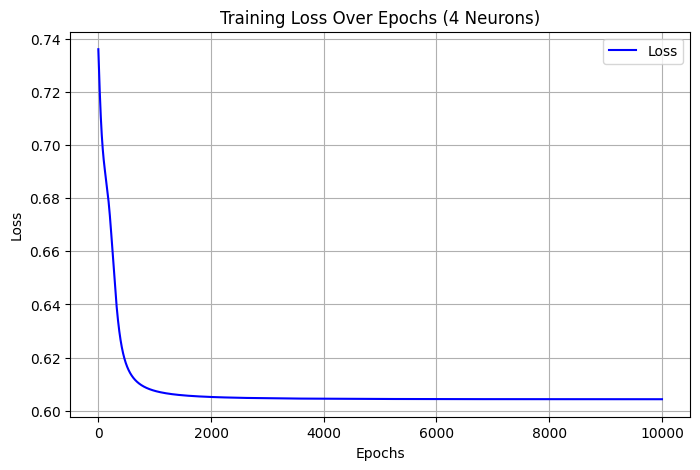


Final Weights of the Network:
Neuron 1 Weights: [0.9747069  0.97847086 0.9999213 ]
Neuron 1 Rounded Weights: [1. 1. 1.]
Neuron 2 Weights: [0.9847761 0.9702486 0.9999012]
Neuron 2 Rounded Weights: [1. 1. 1.]
Neuron 3 Weights: [9.9999058e-01 2.1601087e-05 2.3886123e-05]
Neuron 3 Rounded Weights: [1. 0. 0.]
Neuron 4 Weights: [9.9999416e-01 2.2746832e-05 3.0705942e-05]
Neuron 4 Rounded Weights: [1. 0. 0.]

Final Rule:
h :- b3 and b4.



In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import random

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input)

# Fully Automated Neural Network
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            outputs.append(neuron(xi))

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output

# User-Specified Number of Neurons
num_neurons = 4  # int(input("Enter the number of neurons: "))  # User specifies the number of neurons
input_dim = num_neurons  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(41)
num_samples = 200
X_train = X_train_group2  # Auto-adjusted input dimension
y_train = y_train_group2  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 10000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons)")
plt.legend()
plt.grid(True)
plt.show()

# Print Final Weights After Training
Weights = []
Rounded_weights = []
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    # Round the weights to the nearest number (e.g., nearest integer)
    rounded_weights = np.round(weights, decimals=0)  # Adjust `decimals` as needed (e.g., 0 for integers)
    
    Weights.append(weights)
    Rounded_weights.append(rounded_weights)
    print(f"Neuron {i+1} Weights: {weights}")
    print(f"Neuron {i+1} Rounded Weights: {rounded_weights}")

preds = interpret_neuron_weights(Rounded_weights)
refined_preds = [pred for pred in preds if pred != '1']
final_rule = f"h :- " + " and ".join(refined_preds) + "."
print("\n==========================================")
print("Final Rule:")
print(final_rule)
print("==========================================\n")


In [44]:
torch.sum(y_train_rule2 == 0.0).item()

32

In [42]:
# Concatenate X_train and y_train
dataset = torch.cat([X_train, y_train.unsqueeze(1)], dim=1)  # Add y_train as the last column

# Convert to a NumPy array for better readability (optional)
dataset_np = dataset.numpy()

# Print the dataset as a table
import pandas as pd
columns = [f"X_{i+1}" for i in range(X_train.shape[1])] + ["y"]
df = pd.DataFrame(dataset_np, columns=columns)
print(df)

          X_1       X_2       X_3       X_4    y
0    0.212983  0.905460  0.745468  0.849979  1.0
1    0.141600  0.967326  0.318437  0.223602  0.0
2    0.332864  0.532309  0.791879  0.372126  0.0
3    0.162305  0.580889  0.018616  0.101729  0.0
4    0.607555  0.945041  0.211034  0.783414  1.0
..        ...       ...       ...       ...  ...
495  0.312300  0.738119  0.299022  0.882227  0.0
496  0.145251  0.414121  0.924464  0.290164  0.0
497  0.508965  0.353088  0.676476  0.247723  0.0
498  0.122197  0.311810  0.701652  0.370347  0.0
499  0.116563  0.395662  0.281826  0.915678  0.0

[500 rows x 5 columns]


In [43]:
# Count the number of 1.0 in the 'y' column
num_ones = (df['y'] == 1.0).sum()
print(f"Number of 1.0 in y: {num_ones}")

Number of 1.0 in y: 206


## How to add constraints to the network?

# Appendix

## Normalization Techniques (did not work)


Final Weights of the Network:
Neuron 1 Weights: [0.7219166  0.22277929 0.21102084], Sum: 1.1557
Neuron 2 Weights: [0.6964418  0.12118161 0.10230675], Sum: 0.9199
Neuron 3 Weights: [0.2367234  0.37895483 0.1748372 ], Sum: 0.7905
Neuron 4 Weights: [0.49794722 0.38162884 0.24305673], Sum: 1.1226


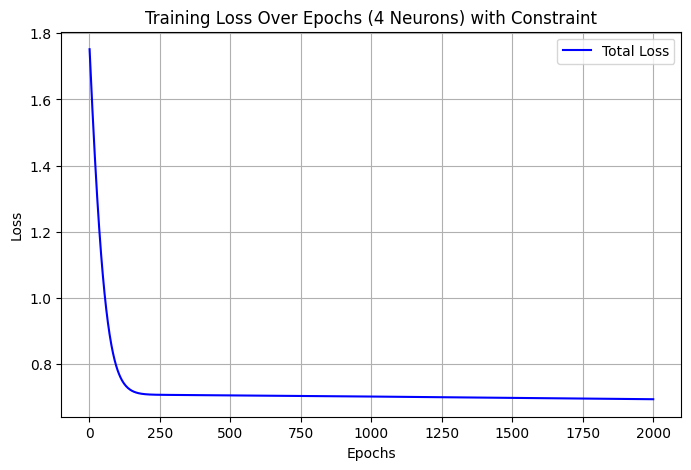

In [5]:
# Re-import necessary libraries after execution state reset
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input), weights.sum()  # Return both output and weight sum

# Fully Automated Neural Network with Constraint
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        total_weight_sum = 0  # To accumulate weight sum across neurons
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            out, weight_sum = neuron(xi)  # Get both the neuron output and weight sum
            outputs.append(out)
            total_weight_sum += weight_sum

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output, total_weight_sum

# User-Specified Number of Neurons
num_neurons = 4  # Set number of neurons
input_dim = 4  # Adjust as needed

# Generate Synthetic Data
torch.manual_seed(42)
num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop with Constraint
num_epochs = 2000
losses = []
lambda_reg = 0.1  # Regularization strength for the constraint

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs, total_weight_sum = model(X_train)
    outputs = outputs.squeeze()
    
    # Compute primary loss
    loss = criterion(outputs, y_train)
    
    # Compute weight constraint loss
    constraint_loss = lambda_reg * (total_weight_sum - num_neurons) ** 2  # (sum(weights) - num_neurons)^2
    
    # Combined loss
    total_loss = loss + constraint_loss

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}, Sum: {weights.sum():.4f}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Total Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons) with Constraint")
plt.legend()
plt.grid(True)
plt.show()



Final Weights of the Network:
Neuron 1 Weights: [0.32997084 0.35701716 0.31196594], Sum: 0.9990
Neuron 2 Weights: [0.4338659  0.30960646 0.25546244], Sum: 0.9989
Neuron 3 Weights: [0.31008956 0.3742087  0.31465062], Sum: 0.9989
Neuron 4 Weights: [0.3890295  0.3213277  0.28858784], Sum: 0.9989
Neuron 5 Weights: [0.38813692 0.29248634 0.31831717], Sum: 0.9989
Neuron 6 Weights: [0.34579784 0.29492566 0.35822597], Sum: 0.9989
Neuron 7 Weights: [0.32062608 0.33341494 0.34491128], Sum: 0.9990
Neuron 8 Weights: [0.3306189  0.2881844  0.38014156], Sum: 0.9989
Neuron 9 Weights: [0.42316687 0.30064487 0.2751344 ], Sum: 0.9989
Neuron 10 Weights: [0.32219338 0.31213874 0.364641  ], Sum: 0.9990


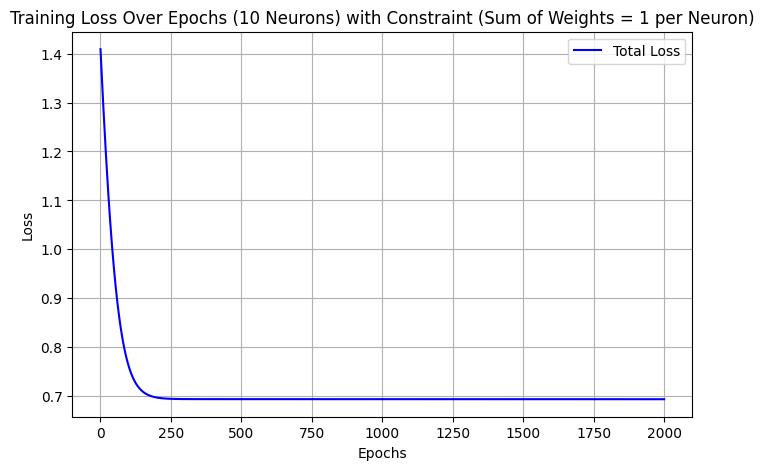

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input), weights.sum()  # Return both output and weight sum

# Fully Automated Neural Network with Constraint
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        weight_sums = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            out, weight_sum = neuron(xi)  # Get both the neuron output and weight sum
            outputs.append(out)
            weight_sums.append(weight_sum)

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output, weight_sums

# User-Specified Number of Neurons
num_neurons = 10  # Set number of neurons
input_dim = 4  # Adjust as needed

# Generate Synthetic Data
torch.manual_seed(42)
num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * X_train[:, 1] > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop with Constraint
num_epochs = 2000
losses = []
lambda_reg = 0.1  # Regularization strength for the constraint

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs, weight_sums = model(X_train)
    outputs = outputs.squeeze()
    
    # Compute primary loss
    loss = criterion(outputs, y_train)
    
    # Compute weight constraint loss
    constraint_loss = lambda_reg * sum((weight_sum - 1) ** 2 for weight_sum in weight_sums)  # (sum(weights) - 1)^2 for each neuron
    
    # Combined loss
    total_loss = loss + constraint_loss

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}, Sum: {weights.sum():.4f}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Total Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons) with Constraint (Sum of Weights = 1 per Neuron)")
plt.legend()
plt.grid(True)
plt.show()




Final Weights of the Network:
Neuron 1 Weights: [0.02985656 0.01733964 0.06608091], Third Weight: 0.0661
Neuron 2 Weights: [0.08144264 0.3690772  0.9526066 ], Third Weight: 0.9526
Neuron 3 Weights: [0.07322497 0.09309963 0.94754463], Third Weight: 0.9475
Neuron 4 Weights: [0.01066896 0.01076307 0.01921028], Third Weight: 0.0192


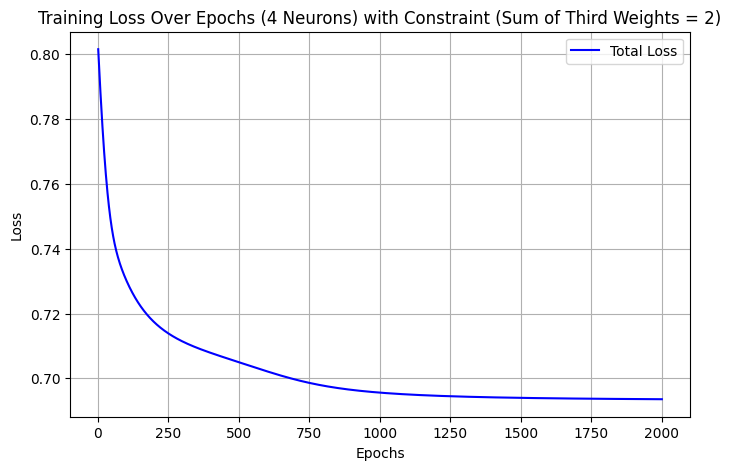

In [7]:
# Re-import necessary libraries after execution state reset
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  

        # Apply log function
        return torch.log(stable_input), weights[2]  # Return both output and third weight

# Fully Automated Neural Network with Constraint
class CustomNeuralNet(nn.Module):
    def __init__(self, num_neurons, input_dim):
        super(CustomNeuralNet, self).__init__()
        self.num_neurons = num_neurons
        self.neurons = nn.ModuleList([CustomNeuron() for _ in range(num_neurons)])
        self.input_dim = input_dim

    def forward(self, x):
        # Assign different input features to different neurons
        outputs = []
        third_weights = []
        for i, neuron in enumerate(self.neurons):
            xi = x[:, [i % self.input_dim]]  # Cycle through input dimensions
            out, third_weight = neuron(xi)  # Get both the neuron output and third weight
            outputs.append(out)
            third_weights.append(third_weight)

        # Sum outputs and apply exponentiation
        output = torch.exp(sum(outputs))
        return output, sum(third_weights)

# User-Specified Number of Neurons
num_neurons = 4  # Set number of neurons
input_dim = 4  # Adjust as needed

# Generate Synthetic Data
# torch.manual_seed(42)
num_samples = 100
X_train = torch.rand(num_samples, input_dim)  # Auto-adjusted input dimension
y_train = (X_train[:, 0] * (1-X_train[:, 1]) > 0.25).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet(num_neurons=num_neurons, input_dim=input_dim)
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop with Constraint
num_epochs = 2000
losses = []
lambda_reg = 0.1  # Regularization strength for the constraint

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs, total_third_weight = model(X_train)
    outputs = outputs.squeeze()
    
    # Compute primary loss
    loss = criterion(outputs, y_train)
    
    # Compute weight constraint loss (sum of third weights should be num_neurons - 2)
    constraint_loss = lambda_reg * (total_third_weight - (num_neurons - 2)) ** 2  
    
    # Combined loss
    total_loss = loss + constraint_loss

    # Backpropagation
    total_loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(total_loss.item())

# Print Final Weights After Training
print("\nFinal Weights of the Network:")
for i, neuron in enumerate(model.neurons):
    weights = torch.sigmoid(neuron.raw_weights).detach().numpy()
    print(f"Neuron {i+1} Weights: {weights}, Third Weight: {weights[2]:.4f}")

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Total Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title(f"Training Loss Over Epochs ({num_neurons} Neurons) with Constraint (Sum of Third Weights = {num_neurons - 2})")
plt.legend()
plt.grid(True)
plt.show()


Weights1: tensor([9.9801e-01, 1.8878e-05, 9.9937e-05], grad_fn=<SigmoidBackward0>).
Weights2: tensor([9.9897e-01, 2.6009e-04, 3.6919e-03], grad_fn=<SigmoidBackward0>).



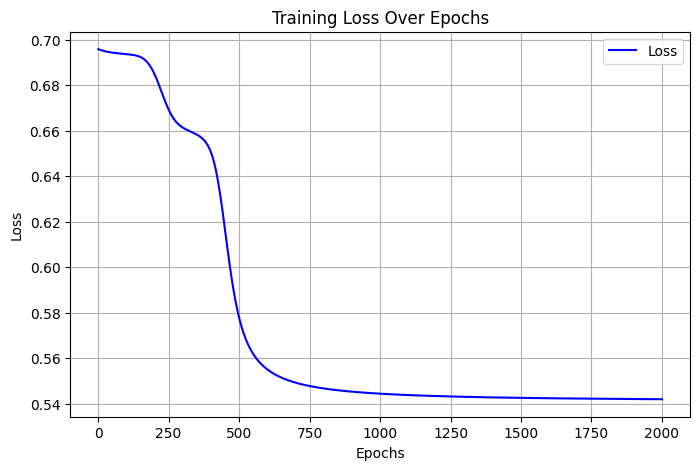

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Custom Activation Function for a Neuron
class CustomNeuron(nn.Module):
    def __init__(self):
        super(CustomNeuron, self).__init__()
        self.raw_weights = nn.Parameter(-10*torch.rand(3))  # Three weights for each neuron

    def forward(self, x):
        # Apply sigmoid to normalize weights between 0 and 1
        weights = torch.sigmoid(self.raw_weights)  

        # Define the three inputs per neuron
        x1 = x
        x2 = 1 - x
        x3 = torch.ones_like(x)

        X1 = weights[0] * x1
        X2 = weights[1] * x2
        X3 = weights[2] * x3

        # Ensuring numerical stability (keeping input in [epsilon, 1])
        stable_input = X1 + X2 + X3 - (X1*X2 + X1*X3 + X2*X3) + (X1*X2*X3) + 1e-6  # No tensor wrapping

        # Apply log function
        return torch.log(stable_input)

# Full Network with Two Neurons (Different Inputs)
class CustomNeuralNet(nn.Module):
    def __init__(self):
        super(CustomNeuralNet, self).__init__()
        self.neuron1 = CustomNeuron()
        self.neuron2 = CustomNeuron()
    
    def forward(self, x):
        # Split input into two separate inputs (each neuron gets a different feature)
        x1 = x[:, [0]]  # Feature for neuron 1
        x2 = x[:, [1]]  # Feature for neuron 2
        
        # Compute neuron outputs
        out1 = self.neuron1(x1)
        out2 = self.neuron2(x2)
        
        # Sum outputs and apply exponentiation
        output = torch.exp(out1 + out2)
        
        return output

# Generate Synthetic Data (Binary Classification with Two Inputs)
torch.manual_seed(42)
num_samples = 10

X_train = (torch.rand(num_samples, 2) > 0.5).float()  # 100 samples, 2 input features
y_train = (X_train[:, 0] * X_train[:, 1]).float()  # Threshold for classification

# Model, Loss, Optimizer
model = CustomNeuralNet()
criterion = nn.BCEWithLogitsLoss()  # Binary Cross-Entropy loss
optimizer = optim.Adam(model.parameters(), lr=0.01)

# Training Loop
num_epochs = 2000
losses = []

for epoch in range(num_epochs):
    optimizer.zero_grad()
    
    # Forward pass
    outputs = model(X_train).squeeze()
    
    # Compute loss
    loss = criterion(outputs, y_train)
    
    # Backpropagation
    loss.backward()
    optimizer.step()

    # Store loss for plotting
    losses.append(loss.item())

print(f'Weights1: {torch.sigmoid(model.neuron1.raw_weights)}.')
print(f'Weights2: {torch.sigmoid(model.neuron2.raw_weights)}.\n')

# Plot the loss curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, num_epochs + 1), losses, label="Loss", color="blue")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss Over Epochs")
plt.legend()
plt.grid(True)
plt.show()
